In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import os

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
urllib.request.urlretrieve(url, "online_retail.xlsx")

('online_retail.xlsx', <http.client.HTTPMessage at 0x2eb891e3b00>)

In [3]:
df = pd.read_excel("online_retail.xlsx")

df.shape
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [5]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [6]:
print(df.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [8]:
missing_values = df.isnull().sum()
print(missing_values)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


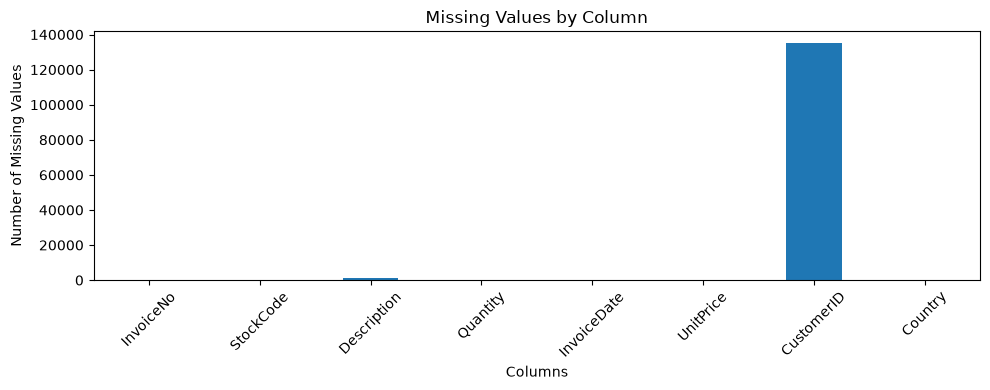

In [9]:
plt.figure(figsize=(10, 4))

df.isnull().sum().plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
#cleaning

In [13]:
df_clean = df.dropna(subset=["CustomerID", "Description"]).copy()
cancelled_mask = (df_clean["InvoiceNo"].astype(str).str.startswith("C"))

df_clean = df_clean.loc[~cancelled_mask].copy()
invalid_mask = ((df_clean["Quantity"] <= 0) |(df_clean["UnitPrice"] <= 0))

df_clean = df_clean.loc[(df_clean["Quantity"] > 0) &(df_clean["UnitPrice"] > 0)].copy()

df_clean = df_clean.drop_duplicates().copy()

In [14]:
df_clean.to_csv("online_retail_cleaned.csv",index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [28]:
# InvoiceDate to datetime
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# sales for each transaction line
df_clean["TotalSales"] = (df_clean["Quantity"] * df_clean["UnitPrice"])

# Extract the month
df_clean["Month"] = (df_clean["InvoiceDate"].dt.to_period("M"))

# Check the results
print("Dataset shape:", df_clean.shape)
display(df_clean.head())

# 5. Save the cleaned dataset
df_clean.to_csv("online_retail_cleaned.csv",index=False)

Dataset shape: (392692, 10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


Monthly Revenue:
Month
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: TotalSales, dtype: float64


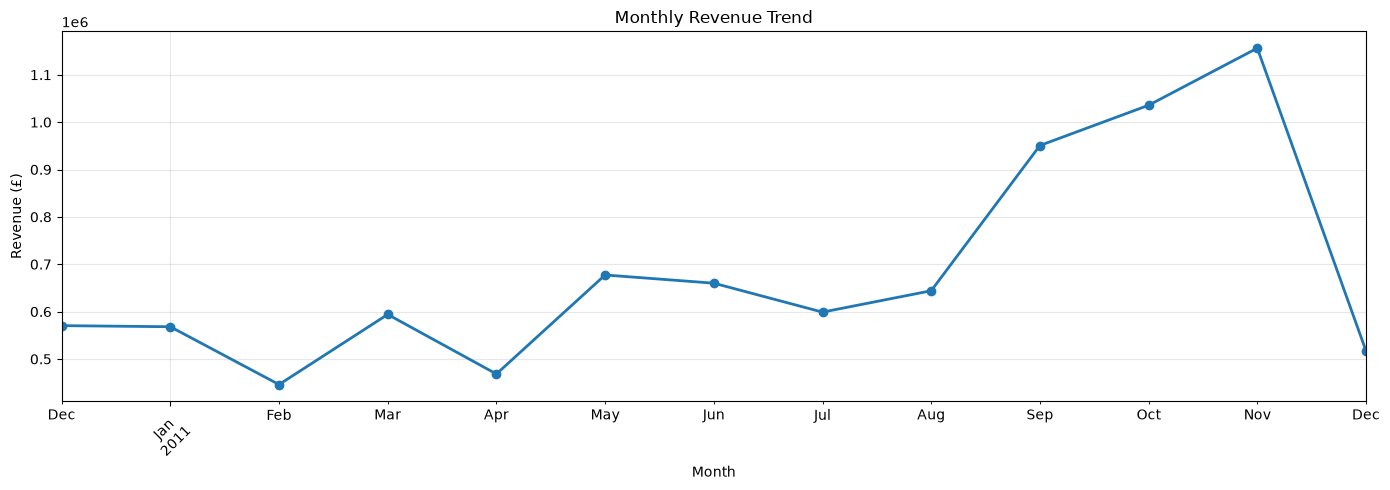

In [29]:
monthly_revenue = (df_clean.groupby("Month")["TotalSales"].sum().sort_index())

print("Monthly Revenue:")
print(monthly_revenue)

plt.figure(figsize=(14, 5))

monthly_revenue.plot(kind="line",marker="o",linewidth=2
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Top 10 Products by Quantity Sold:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64


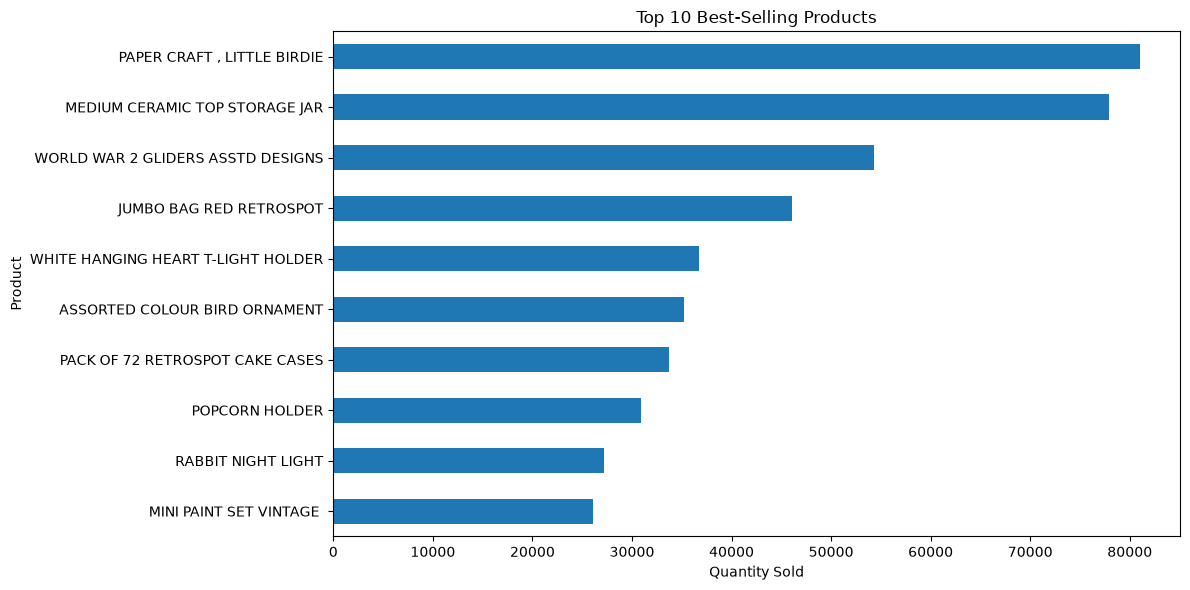

In [30]:
#top 10 products by quantity sold
top_products = (df_clean.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10))

print("Top 10 Products by Quantity Sold:")
print(top_products)

plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Top 10 Products by Revenue:
Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: TotalSales, dtype: float64


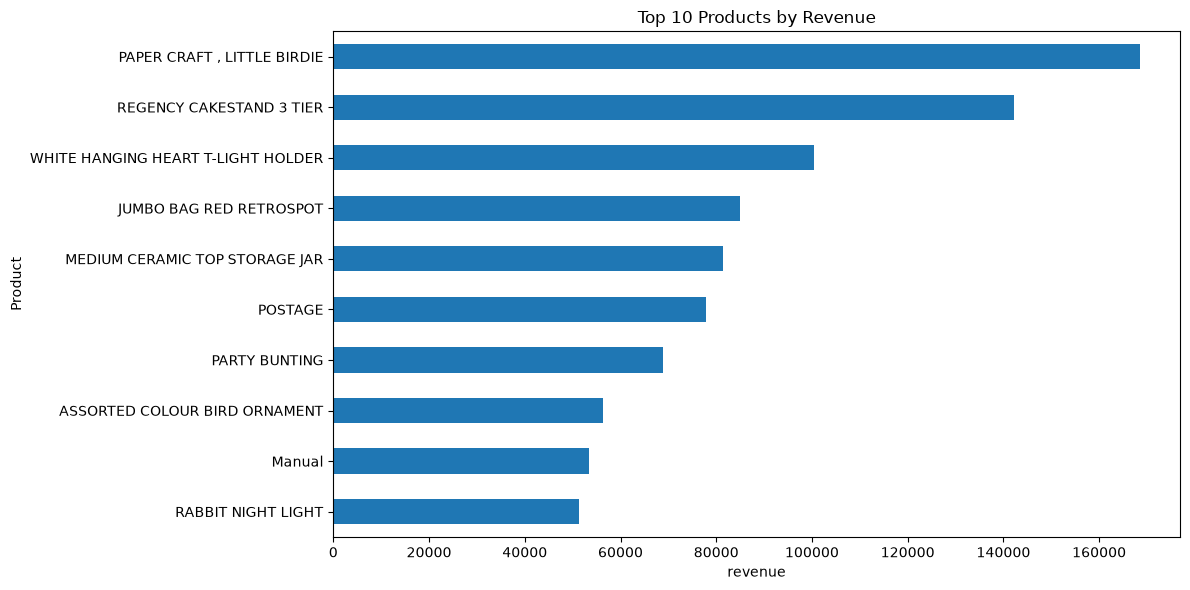

In [31]:
#top 10 product by revenue
top_products_revenue = (df_clean.groupby("Description")["TotalSales"].sum().sort_values(ascending=False).head(10))

print("Top 10 Products by Revenue:")
print(top_products_revenue)

plt.figure(figsize=(12, 6))

top_products_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()



In [32]:
#Customer Purchasing Behavior
unique_customers = df_clean["CustomerID"].nunique()

print("Total Unique Customers:", unique_customers)

Total Unique Customers: 4338


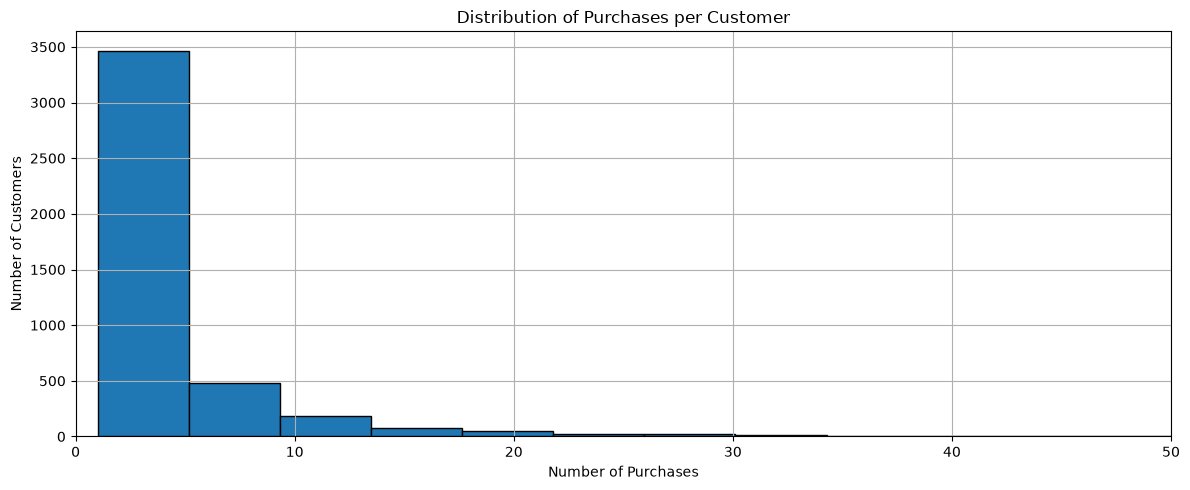

In [33]:
purchases_per_customer = (df_clean.groupby("CustomerID")["InvoiceNo"].nunique())

plt.figure(figsize=(12, 5))

purchases_per_customer.hist(bins=50,edgecolor="black")

plt.title("Distribution of Purchases per Customer")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Customers")
plt.xlim(0, 50)
plt.tight_layout()
plt.show()

Top 15 Countries by Revenue:
Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Japan               37416.370
Norway              36165.440
Portugal            33375.840
Finland             22546.080
Singapore           21279.290
Name: TotalSales, dtype: float64


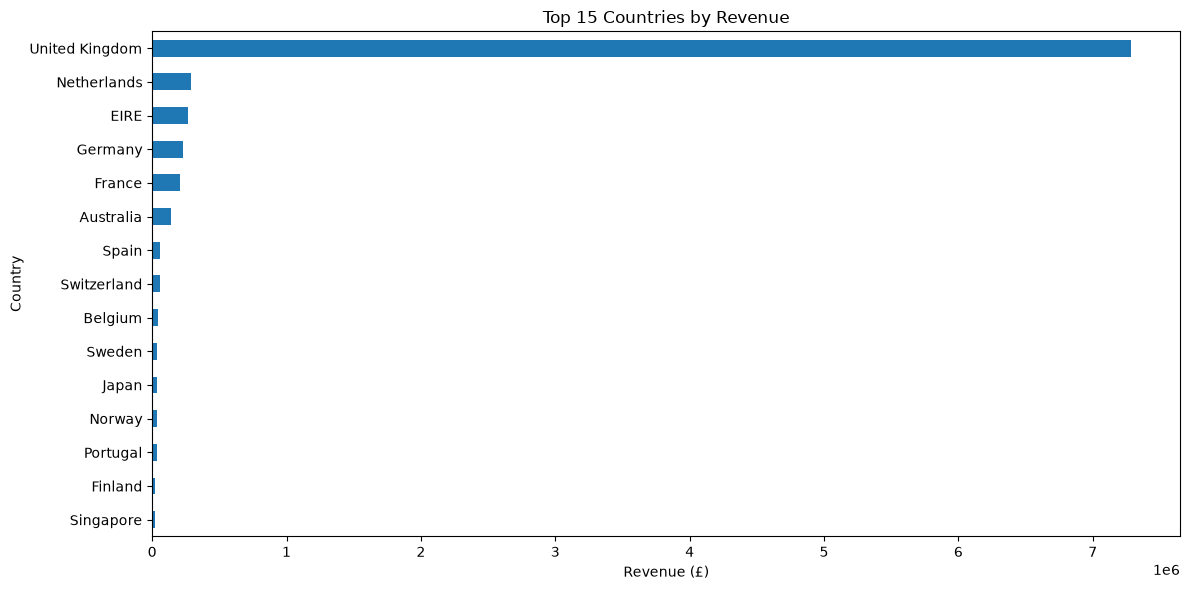

In [34]:
#Revenue by Country
revenue_by_country = (df_clean.groupby("Country")["TotalSales"].sum().sort_values(ascending=False).head(15))

print("Top 15 Countries by Revenue:")
print(revenue_by_country)

plt.figure(figsize=(12, 6))

revenue_by_country.sort_values().plot(kind="barh")

plt.title("Top 15 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [35]:
#rfm
from datetime import timedelta
reference_date = (df_clean["InvoiceDate"].max()+ timedelta(days=1))
print("Reference date:", reference_date)

Reference date: 2011-12-10 12:50:00


In [36]:
rfm = df_clean.groupby("CustomerID").agg({"InvoiceDate": lambda x:(reference_date - x.max()).days,"InvoiceNo": "count","TotalSales": "sum"})

# Give the columns meaningful names
rfm.columns = ["Recency", "Frequency", "Monetary"]

# Display the first 10 customers
display(rfm.head(10))

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,182,4310.00
12348.0,75,31,1797.24
12349.0,19,73,1757.55
12350.0,310,17,334.40
12352.0,36,85,2506.04
12353.0,204,4,89.00
12354.0,232,58,1079.40
12355.0,214,13,459.40


In [37]:
# Top 10 customers by monetary value
top_value_customers = rfm.sort_values("Monetary",ascending=False).head(10)

print("Top 10 Customers by Monetary Value:")
display(top_value_customers)

Top 10 Customers by Monetary Value:


,Recency,Frequency,Monetary
CustomerID,,,
14646.0,2,2076,280206.02
18102.0,1,431,259657.30
17450.0,8,336,194390.79
16446.0,1,3,168472.50
14911.0,1,5670,143711.17
12415.0,24,714,124914.53
14156.0,10,1395,117210.08
17511.0,3,963,91062.38
16029.0,39,241,80850.84


In [38]:
# Customers with the lowest recency
most_recent_customers = rfm.sort_values("Recency",ascending=True).head(10)

print("10 Most Recently Active Customers:")
display(most_recent_customers)

10 Most Recently Active Customers:


,Recency,Frequency,Monetary
CustomerID,,,
17364.0,1,406,4462.68
12433.0,1,420,13375.87
13599.0,1,246,5149.92
13536.0,1,178,3444.39
16933.0,1,44,563.23
17581.0,1,439,11025.24
15898.0,1,84,1383.83
16892.0,1,97,518.19
17644.0,1,157,2895.64


In [39]:
rfm.to_csv("customer_rfm.csv")

In [40]:
# Step 1: Recency score
rfm["R_Score"] = pd.qcut(rfm["Recency"],4,labels=[4, 3, 2, 1],duplicates="drop")

# Step 2: Frequency score
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"),4,labels=[1, 2, 3, 4],duplicates="drop")

# Step 3: Monetary score
rfm["M_Score"] = pd.qcut(rfm["Monetary"],4,labels=[1, 2, 3, 4],duplicates="drop")

# Step 4: Combine the scores
rfm["RFM_Score"] = (rfm["R_Score"].astype(str) +rfm["F_Score"].astype(str) +rfm["M_Score"].astype(str))

# Step 5: View the results
display(rfm.head(10))

# Step 6: Save the scored customer data
rfm.to_csv("customer_rfm_scored.csv")



,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,4,114
12347.0,2,182,4310.00,4,4,4,444
12348.0,75,31,1797.24,2,2,4,224
12349.0,19,73,1757.55,3,3,4,334
12350.0,310,17,334.40,1,1,2,112
12352.0,36,85,2506.04,3,3,4,334
12353.0,204,4,89.00,1,1,1,111
12354.0,232,58,1079.40,1,3,3,133
12355.0,214,13,459.40,1,1,2,112


In [100]:
#k-means
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
# Select the three original RFM features
features = ["Recency", "Frequency", "Monetary"]

X = rfm[features].copy()

# Create the scaler
scaler = StandardScaler()

# Standardize the RFM measurements
X_scaled = scaler.fit_transform(X)

print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)

Original data shape: (4338, 3)
Scaled data shape: (4338, 3)


In [104]:
def segment_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4:
        return "Loyal"
    elif row["M_Score"] >= 4:
        return "High-Value"
    elif row["R_Score"] <= 2:
        return "Inactive"
    else:
        return "Occasional"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)
print(rfm[["Recency", "Frequency", "Monetary","RFM_Score", "Segment"]].head(10))
print("\nCustomer Segment Counts:")
count=rfm["Segment"].value_counts()
print(count)

            Recency  Frequency  Monetary RFM_Score     Segment
CustomerID                                                    
12346.0         326          1  77183.60       114  High-Value
12347.0           2        182   4310.00       444       Loyal
12348.0          75         31   1797.24       224  High-Value
12349.0          19         73   1757.55       334  High-Value
12350.0         310         17    334.40       112    Inactive
12352.0          36         85   2506.04       334  High-Value
12353.0         204          4     89.00       111    Inactive
12354.0         232         58   1079.40       133    Inactive
12355.0         214         13    459.40       112    Inactive
12356.0          23         59   2811.43       334  High-Value

Customer Segment Counts:
Segment
Inactive      1916
Occasional    1232
High-Value     634
Loyal          556
Name: count, dtype: int64


Customers in each segment:
Segment
High-Value     634
Inactive      1916
Loyal          556
Occasional    1232
Name: count, dtype: int64


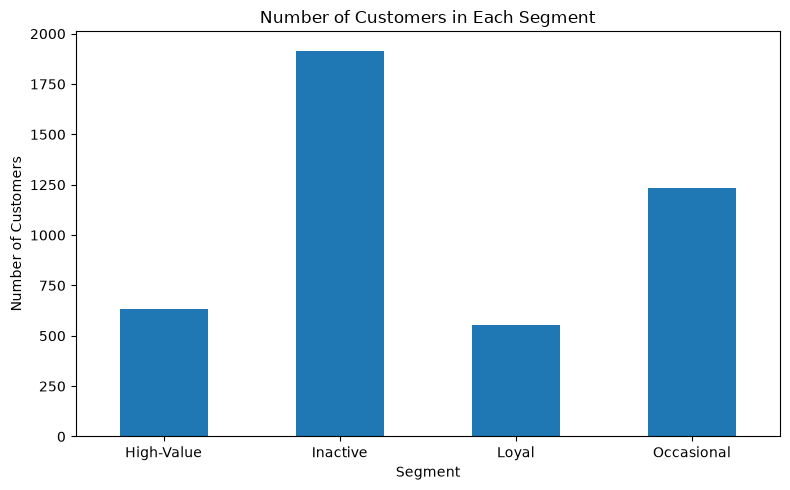

In [107]:
segment_counts = (rfm["Segment"].value_counts().sort_index())

print("Customers in each segment:")
print(segment_counts)

plt.figure(figsize=(8, 5))

segment_counts.plot(kind="bar")

plt.title("Number of Customers in Each Segment")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [108]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [109]:
# Find the earliest transaction date
min_date = df_clean["InvoiceDate"].min()

# Find the latest transaction date
max_date = df_clean["InvoiceDate"].max()

print("Earliest date:", min_date)
print("Latest date:", max_date)

Earliest date: 2010-12-01 08:26:00
Latest date: 2011-12-09 12:50:00


In [110]:
# Split data chronologically for time-series validation
split_date = min_date + (max_date - min_date) * 0.8

df_train = df_clean[df_clean["InvoiceDate"] < split_date].copy()
df_test = df_clean[df_clean["InvoiceDate"] >= split_date].copy()

print(f"Training period: {df_train['InvoiceDate'].min()} to {df_train['InvoiceDate'].max()}")
print(f"Test period: {df_test['InvoiceDate'].min()} to {df_test['InvoiceDate'].max()}")
print(f"Training rows: {len(df_train):,}, Test rows: {len(df_test):,}")

Training period: 2010-12-01 08:26:00 to 2011-09-25 16:06:00
Test period: 2011-09-26 07:35:00 to 2011-12-09 12:50:00
Training rows: 255,052, Test rows: 137,640


In [111]:
# Define prediction window
prediction_date = split_date
label_end = prediction_date + timedelta(days=30)

# Identify customers who purchased in next 30 days
future_customers = df_clean[(df_clean["InvoiceDate"] >= prediction_date) & (df_clean["InvoiceDate"] < label_end)]["CustomerID"].unique()

print(f"Customers who repurchased in next 30 days: {len(future_customers)}")

Customers who repurchased in next 30 days: 1374


In [112]:
# Create RFM features from training data
rfm_train = df_train.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (prediction_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalSales": "sum"
})

rfm_train.columns = ["Recency", "Frequency", "Monetary"]
rfm_train["Target"] = rfm_train.index.isin(future_customers).astype(int)

print("Target distribution:")
print(rfm_train["Target"].value_counts())
print(f"Repurchase rate: {rfm_train['Target'].mean()*100:.2f}%")

Target distribution:
Target
0    2534
1    1016
Name: count, dtype: int64
Repurchase rate: 28.62%


In [113]:
# Prepare features and target
X = rfm_train[["Recency", "Frequency", "Monetary"]].copy()
y = rfm_train["Target"].copy()

# Train-validation split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale features for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print(f"Training set: {len(X_train)}, Validation set: {len(X_val)}")
print(f"Training target distribution:\n{y_train.value_counts()}")

Training set: 2840, Validation set: 710
Training target distribution:
Target
0    2027
1     813
Name: count, dtype: int64


In [114]:
# Model 1: Logistic Regression
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_val_scaled)
y_pred_proba_lr = lr_model.predict_proba(X_val_scaled)[:, 1]

print("LOGISTIC REGRESSION")
print(classification_report(y_val, y_pred_lr, target_names=["No Repurchase", "Repurchase"], zero_division=0))

LOGISTIC REGRESSION
               precision    recall  f1-score   support

No Repurchase       0.76      0.96      0.85       507
   Repurchase       0.72      0.24      0.36       203

     accuracy                           0.76       710
    macro avg       0.74      0.60      0.61       710
 weighted avg       0.75      0.76      0.71       710



In [115]:
# Model 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_val)
y_pred_proba_rf = rf_model.predict_proba(X_val)[:, 1]

print("RANDOM FOREST")
print(classification_report(y_val, y_pred_rf, target_names=["No Repurchase", "Repurchase"], zero_division=0))

RANDOM FOREST
               precision    recall  f1-score   support

No Repurchase       0.76      0.95      0.85       507
   Repurchase       0.68      0.26      0.38       203

     accuracy                           0.75       710
    macro avg       0.72      0.61      0.61       710
 weighted avg       0.74      0.75      0.71       710



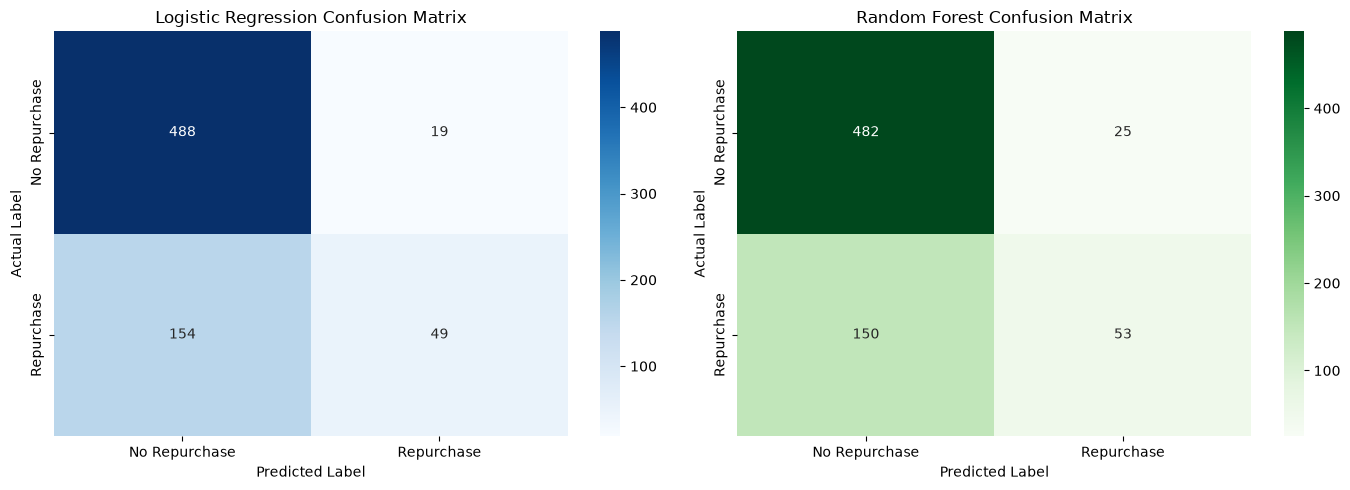

In [116]:

# Confusion Matrix 

cm_lr = confusion_matrix(y_val, y_pred_lr)
cm_rf = confusion_matrix(y_val, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Confusion Matrix
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Repurchase", "Repurchase"],
    yticklabels=["No Repurchase", "Repurchase"],
    ax=axes[0],
    vmax=max(cm_lr.max(), cm_rf.max())
)

axes[0].set_title("Logistic Regression Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

# Random Forest Confusion Matrix
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Repurchase", "Repurchase"],
    yticklabels=["No Repurchase", "Repurchase"],
    ax=axes[1],
    vmax=max(cm_lr.max(), cm_rf.max())
)

axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


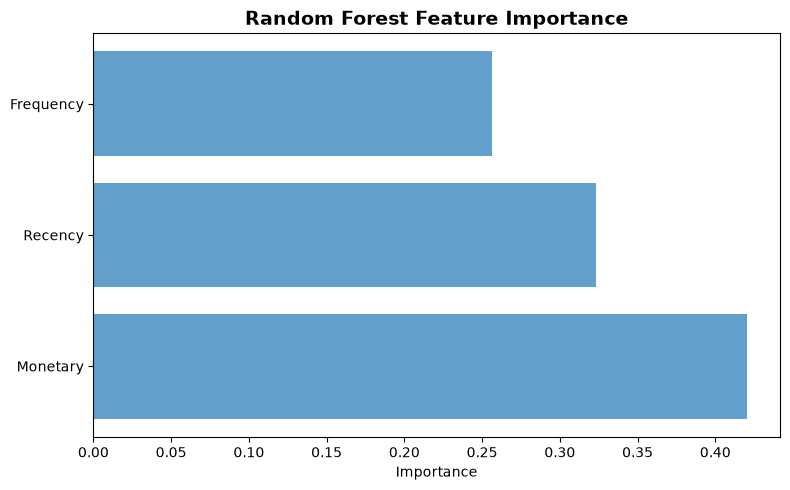

In [91]:
# Feature importance (Random Forest)
feature_importance = pd.DataFrame({
    "Feature": ["Recency", "Frequency", "Monetary"],
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(8, 5))
plt.barh(feature_importance["Feature"], feature_importance["Importance"], alpha=0.7)
plt.title("Random Forest Feature Importance", fontsize=14, fontweight="bold")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

feature_importance.to_csv("feature_importance.csv", index=False)

In [95]:
# Model comparison
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy_score(y_val, y_pred_lr), accuracy_score(y_val, y_pred_rf)],
    "Precision": [precision_score(y_val, y_pred_lr, zero_division=0), precision_score(y_val, y_pred_rf, zero_division=0)],
    "Recall": [recall_score(y_val, y_pred_lr, zero_division=0), recall_score(y_val, y_pred_rf, zero_division=0)],
    "F1-Score": [f1_score(y_val, y_pred_lr, zero_division=0), f1_score(y_val, y_pred_rf, zero_division=0)],
})

print("MODEL COMPARISON:")
print(model_comparison.round(3))

model_comparison.to_csv("model_comparison.csv", index=False)

MODEL COMPARISON:
                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression     0.756      0.721   0.241     0.362
1        Random Forest     0.754      0.679   0.261     0.377
